# RAG over the Constitution of India: Baseline vs. Re-Ranking

Question answering over the **articles** of the Constitution of India, comparing two retrieval pipelines
over the same 1,035 chunks:

- **Pipeline 1 (baseline):** bi-encoder top 10 → top 3 → LLM → Answer 1
- **Pipeline 2 (re-ranking):** the same top 10 → cross-encoder → top 3 → LLM → Answer 2

**Sections:** 0. Setup · 1. Extraction · 2. Articles · 3. Chunking · 4. Embeddings · 5. Retrieval ·
6. Generation · 7. Failure modes · 8. Selected cases · 9. Latency · 10. Metrics

## 0. Setup

In [53]:
# Install the libraries used in this notebook (run once)
%pip install --no-cache-dir pdfplumber sentence-transformers google-genai python-dotenv matplotlib

Note: you may need to restart the kernel to use updated packages.


In [54]:
# Imports for PDF text extraction
import re
import pdfplumber

In [55]:
# The PDF and the pages that hold the articles (1-indexed: Art. 1 starts on p.33, Art. 395 ends on p.283)
PDF_PATH = "data/constitution_eng.pdf"
FIRST_PAGE = 33
LAST_PAGE = 283

## 1. Extract the article text (without footnotes)

In [56]:
# Footnotes sit below a horizontal separator line: crop each page to the area above it
def crop_above_footnotes(page):
    # pdfplumer has different attributes for lines and rects, so we need to filter out the lines that are actually separators
    separators = [l for l in page.lines if abs(l["top"] - l["bottom"]) < 1 and (l["x1"] - l["x0"]) > 100] # a line could be horizontal or vertical, this line checks that
    if not separators:
        return page
    cut_y = min(l["top"] for l in separators)
    return page.crop((0, 0, page.width, cut_y))


In [57]:
# Drop superscript footnote markers like ¹[ (6-6.5pt) while keeping the body text (9-10pt)
def drop_small_chars(page, min_size=7):
    return page.filter(lambda obj: obj.get("object_type") != "char" or obj["size"] >= min_size)

In [58]:
# Clean one page: crop footnotes, drop markers, remove running headers and page numbers
HEADER_RE = re.compile(r"^\d*\s*THE CONSTITUTION OF INDIA$"   # running title
                       r"|^\(Part [^)]*\)$"                    # (Part III.—...)
                       r"|^\d+$")                              # bare page number

def clean_page(page):
    page = crop_above_footnotes(page)
    page = drop_small_chars(page)
    text = page.extract_text() or ""
    return "\n".join(ln for ln in text.splitlines()
                     if not HEADER_RE.match(ln.strip()))

### Cache the extracted text

In [59]:
# Extract all article pages once and cache the text (later runs just read the file)
import os

CACHE = "data/articles_text.txt"

if os.path.exists(CACHE): # agar already exust karta hai, then read
    with open(CACHE, encoding="utf-8") as f:
        articles_text = f.read()
else:
    with pdfplumber.open(PDF_PATH) as pdf: # for the first time, extract and cache
        articles_text = "\n".join(clean_page(pdf.pages[i]) for i in range(FIRST_PAGE - 1, LAST_PAGE))
    with open(CACHE, "w", encoding="utf-8") as f:
        f.write(articles_text)

## 2. Split the text into articles

The idea is to separate the title amd the body

In [60]:
# Regex for an article heading: number (19, 21A, 243ZH) + a title that ends in an em-dash
ARTICLE_RE = re.compile(
    r"^\[?(\d{1,3}[A-Z]{0,3})\.\s+"        # "19. " or "[21A. " at the start of a line
    r"([^—⎯\n]+(?:\n[^—⎯\n]+){0,2}?)"      # title: up to 3 lines, no dash inside
    r"\s*[—⎯]",                             # the title ends at an em-dash
    re.M,
)

In [61]:
# Find every article heading in the text
matches = list(ARTICLE_RE.finditer(articles_text))
matches


[<re.Match object; span=(35, 71), match='1. Name and territory of the Union.—'>,
 <re.Match object; span=(406, 451), match='2. Admission or establishment of new States.—'>,
 <re.Match object; span=(567, 615), match='[2A. [Sikkim to be associated with the Union.].—'>,
 <re.Match object; span=(705, 797), match='3. Formation of new States and alteration of area>,
 <re.Match object; span=(2026, 2185), match='4. Laws made under articles 2 and 3 to provide fo>,
 <re.Match object; span=(2786, 2842), match='5. Citizenship at the commencement of the Constit>,
 <re.Match object; span=(3225, 3311), match='6. Rights of citizenship of certain persons who h>,
 <re.Match object; span=(4429, 4487), match='7. Rights of citizenship of certain migrants to P>,
 <re.Match object; span=(5147, 5232), match='8. Rights of citizenship of certain persons of In>,
 <re.Match object; span=(5960, 6044), match='9. Persons voluntarily acquiring citizenship of a>,
 <re.Match object; span=(6250, 6296), match='10. Contin

In [62]:
# Inspect the first match: span = character positions inside articles_text
matches[0], matches[0].start(), matches[0].group(1), matches[0].group(2)

(<re.Match object; span=(35, 71), match='1. Name and territory of the Union.—'>,
 35,
 '1',
 'Name and territory of the Union.')

35 = matches[0].start(), the index of the first matched character (the 1 of 1. Name...). </br>
71 = matches[0].end(), the index just after the last matched character (one past the —).

In [63]:
# Part / section headings get stuck to the end of the previous article: peel them off
END_PUNCT = (".", ";", ":", "—", "⎯", "]", ",", "-", ")")

def split_trailing_headings(body):
    lines = body.splitlines()
    headings = []
    while lines and not lines[-1].rstrip().endswith(END_PUNCT):
        headings.insert(0, lines.pop().strip())   # pop from the end, keep original order
    return "\n".join(lines), headings

In [64]:
# Cut the text between consecutive headings -> one dict per article (number, title, body)
articles = []
for i, m in enumerate(matches):
    end = matches[i + 1].start() if i + 1 < len(matches) else len(articles_text)
    body, trailing = split_trailing_headings(articles_text[m.end():end].strip())

    articles.append({
        "number": m.group(1),
        "title":  " ".join(m.group(2).split()).rstrip("."),   # join the wrapped lines
        "body":  body,
    })

print(len(articles))

500


In [65]:
# Example: Article 3 (its proviso continues onto the next PDF page)
articles[3]

{'number': '3',
 'title': 'Formation of new States and alteration of areas, boundaries or names of existing States',
 'body': 'Parliament may by law—\n(a) form a new State by separation of territory from any\nState or by uniting two or more States or parts of States or by\nuniting any territory to a part of any State;\n(b) increase the area of any State;\n(c) diminish the area of any State;\n(d) alter the boundaries of any State;\n(e) alter the name of any State:\n[Provided that no Bill for the purpose shall be introduced in\neither House of Parliament except on the recommendation of the\nPresident and unless, where the proposal contained in the Bill affects the\narea, boundaries or name of any of the States ***, the Bill has been\nreferred by the President to the Legislature of that State for expressing\nits views thereon within such period as may be specified in the reference\nor within such further period as the President may allow and the period\nso specified or allowed has expired

### Known issue: Part headings stuck to the previous article

Article 4 chunk ends with the start of the next part (\nPART II\nCITIZENSHIP'). This can affect the ranking of chunking. </br>

For Article 4 the harm is small: "Citizenship" is one word in an article about altering States, so it pulls the embedding only slightly. It matters more where the heading is longer or closer in meaning, like Article 11 picking up "FUNDAMENTAL RIGHTS".

In [66]:
# Check: Article 4 no longer ends with 'PART II / CITIZENSHIP'
articles[4] # now fixed

{'number': '4',
 'title': 'Laws made under articles 2 and 3 to provide for the amendment of the First and the Fourth Schedules and supplemental, incidental and consequential matters',
 'body': '(1) Any law referred to in\narticle 2 or article 3 shall contain such provisions for the amendment of\nthe First Schedule and the Fourth Schedule as may be necessary to give\neffect to the provisions of the law and may also contain such\nsupplemental, incidental and consequential provisions (including\nprovisions as to representation in Parliament and in the Legislature or\nLegislatures of the State or States affected by such law) as Parliament\nmay deem necessary.\n(2) No such law as aforesaid shall be deemed to be an amendment\nof this Constitution for the purposes of article 368.'}

## 3. Chunking


                    Article body
                         │
          ≤ 1000 chars? ─┼─ yes → 1 chunk (whole article)
                         │
                         no
                         ▼
          split at numbered clauses (1), (2), (3)…
                         │
          each clause ≤ 1000? ─┼─ yes → 1 chunk per clause
                               │
                               no
                               ▼
          split at line boundaries into ~1000-char windows
                         │
                         ▼
     every chunk gets "Article N — title" put in front


In [67]:
# Chunking settings: max chunk size and the clause-boundary regex
MAX_CHARS = 1000   # ~256 tokens, the bi-encoder's input limit

# split *before* a line starting with a numbered clause: (1), (2), (1A), [(3) ...
CLAUSE_RE = re.compile(r"^(?=\[?\(\d+[A-Z]?\)\s)", re.M)

In [68]:
# Fallback: split text that is still too long at line breaks into ~1000-char windows
def window_split(text, max_chars=MAX_CHARS):
    windows, buf = [], ""
    for line in text.splitlines():
        if buf and len(buf) + len(line) + 1 > max_chars:   # adding this line would overflow
            windows.append(buf)                            # close the current window
            buf = line                                     # start a new one with this line
        else:
            buf = buf + "\n" + line if buf else line
    if buf:
        windows.append(buf)                                # don't lose the last window
    return windows

In [69]:
# Build the chunks: article -> clauses -> line windows, each prefixed with 'Article N — title'
chunks = []
for a in articles:
    prefix = f"Article {a['number']} — {a['title']}\n"

    # level 1: short article stays whole, long one splits at clauses
    if len(a["body"]) <= MAX_CHARS:
        pieces = [a["body"]]
    else:
        pieces = [p.strip() for p in CLAUSE_RE.split(a["body"]) if p.strip()]

    # level 2: any clause still too long gets windowed by lines
    final = []
    for p in pieces:
        final.extend(window_split(p) if len(p) > MAX_CHARS else [p])

    for j, piece in enumerate(final):
        chunks.append({
            "chunk_id": f"{a['number']}_{j}",   # "19_2" = Article 19, piece 2
            "article":  a["number"],
            "text":     prefix + piece,         # every chunk knows its article
        })

print(len(chunks))


1035


In [70]:
# Chunk size check: (max, min, mean) characters
lens = [len(c["text"]) for c in chunks]
max(lens), min(lens), sum(lens) / len(lens)

(1124, 53, 509.57294685990337)

In [71]:
# Save the chunks to data/chunks.json
import json

# save chunks so the web explorer (and anything else) can reuse them without re-running the notebook
titles = {a["number"]: a["title"] for a in articles}
chunks_out = [{"chunk_id": c["chunk_id"],
               "article":  c["article"],
               "title":    titles[c["article"]],
               "text":     c["text"]} for c in chunks]

with open("data/chunks.json", "w", encoding="utf-8") as f:
    json.dump(chunks_out, f, indent=2, ensure_ascii=False)
print("saved", len(chunks_out), "chunks -> data/chunks.json")

saved 1035 chunks -> data/chunks.json


In [72]:
# Article 19 is long, so it is split at its numbered clauses: 19_0 = clause (1), 19_1 = clause (2), ...
for c in chunks:
    if c["article"] == "19":
        print(c["chunk_id"], len(c["text"]), "chars |", c["text"].splitlines()[1][:70])

19_0 483 chars | (1) All citizens shall have the right—
19_1 567 chars | [(2) Nothing in sub-clause (a) of clause (1) shall affect the operatio
19_2 411 chars | (3) Nothing in sub-clause (b) of the said clause shall affect the oper
19_3 423 chars | (4) Nothing in sub-clause (c) of the said clause shall affect the oper
19_4 461 chars | (5) Nothing in [sub-clauses (d) and (e)] of the said clause shall affe
19_5 905 chars | (6) Nothing in sub-clause (g) of the said clause shall affect the oper


## 4. Embeddings (bi-encoder index)

In [73]:
# Imports for the embedding model
from sentence_transformers import SentenceTransformer
import numpy as np

In [74]:
# Load the bi-encoder (max_seq_length = 256 tokens, which is why chunks are kept to ~1000 chars)
bi_encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
print(bi_encoder.max_seq_length)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1272.46it/s]


256


In [75]:
# Embed every chunk once (normalised, so dot product = cosine similarity)
chunk_texts = [c["text"] for c in chunks]
chunk_embs = bi_encoder.encode(
    chunk_texts,
    batch_size=64,
    show_progress_bar=True,
    normalize_embeddings=True,    # unit length, so dot product == cosine similarity
)
print(chunk_embs.shape)

Batches: 100%|██████████| 17/17 [00:40<00:00,  2.40s/it]

(1035, 384)


In [76]:
# save the embeddings in the same order as data/chunks.json (row i = chunk i)
np.save("data/chunk_embs.npy", chunk_embs)
print("saved", chunk_embs.shape, "-> data/chunk_embs.npy")

saved (1035, 384) -> data/chunk_embs.npy


## 5. Retrieval: Pipeline 1 (bi-encoder) and Pipeline 2 (cross-encoder re-ranking)

In [77]:
# Timer for latency measurements
import time

In [78]:
# Pipeline 1: bi-encoder retrieval - score every chunk against the query, keep the top 10
def retrieve(query, k=10):
    t0 = time.perf_counter()
    q = bi_encoder.encode(query, normalize_embeddings=True) # same model, same normalization
    scores = chunk_embs @ q # (1035,) cosine scores
    top_idx = np.argsort(-scores)[:k] # indices of the k highest
    elapsed = time.perf_counter() - t0

    results = [{"rank": r + 1,
                "chunk_id": chunks[i]["chunk_id"],
                "score": float(scores[i]),
                "text": chunks[i]["text"]}
               for r, i in enumerate(top_idx)]
    return results, elapsed

In [79]:
# Import for re-ranking
from sentence_transformers import CrossEncoder

In [80]:
# Pipeline 2: the cross-encoder scores each (query, chunk) pair jointly and re-sorts the 10 candidates
cross_encoder = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")

def rerank(query, candidates, k=3):
    t0 = time.perf_counter()
    pairs = [(query, c["text"]) for c in candidates] # 10 (query, chunk) pairs
    ce_scores = cross_encoder.predict(pairs) # one score per pair
    elapsed = time.perf_counter() - t0

    reranked = [dict(c, ce_score=float(s)) for c, s in zip(candidates, ce_scores)]
    reranked.sort(key=lambda c: c["ce_score"], reverse=True)
    for new_rank, c in enumerate(reranked, 1):
        c["new_rank"] = new_rank # c["rank"] still holds the bi-encoder rank
    return reranked[:k], reranked, elapsed

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 2670.15it/s]


In [81]:
# Try both pipelines on one query: bi-encoder top 10
query = "Can the State make special laws only for women?"

top10, t_bi = retrieve(query)
top3_rr, all_rr, t_ce = rerank(query, top10)

top10

[{'rank': 1,
  'chunk_id': '15_2',
  'score': 0.559055745601654,
  'text': 'Article 15 — Prohibition of discrimination on grounds of religion, race, caste, sex or place of birth\n(3) Nothing in this article shall prevent the State from making any special\nprovision for women and children.'},
 {'rank': 2,
  'chunk_id': '246_2',
  'score': 0.5354660749435425,
  'text': 'Article 246 — Subject-matter of laws made by Parliament and by the Legislatures of States\n(3) Subject to clauses (1) and (2), the Legislature of any State *** has\nexclusive power to make laws for such State or any part thereof with respect to\nany of the matters enumerated in List II in the Seventh Schedule (in this\nConstitution referred to as the “State List”).'},
 {'rank': 3,
  'chunk_id': '15_3',
  'score': 0.4915139973163605,
  'text': 'Article 15 — Prohibition of discrimination on grounds of religion, race, caste, sex or place of birth\n[(4) Nothing in this article or in clause (2) of article 29 shall prevent the\

In [82]:
# Re-ranked top 3 for the same query
top3_rr

[{'rank': 1,
  'chunk_id': '15_2',
  'score': 0.559055745601654,
  'text': 'Article 15 — Prohibition of discrimination on grounds of religion, race, caste, sex or place of birth\n(3) Nothing in this article shall prevent the State from making any special\nprovision for women and children.',
  'ce_score': 6.14552640914917,
  'new_rank': 1},
 {'rank': 9,
  'chunk_id': '15_4',
  'score': 0.4567544758319855,
  'text': 'Article 15 — Prohibition of discrimination on grounds of religion, race, caste, sex or place of birth\n[(5) Nothing in this article or in sub-clause (g) of clause (1) of article 19\nshall prevent the State from making any special provision, by law, for the\nadvancement of any socially and educationally backward classes of citizens or\nfor the Scheduled Castes or the Scheduled Tribes in so far as such special\nprovisions relate to their admission to educational institutions including private\neducational institutions, whether aided or unaided by the State, other than the\nmin

In [83]:
# Rank shifts: bi-encoder rank -> cross-encoder rank for all 10 candidates
for c in all_rr:
    print(f"bi #{c['rank']:>2} -> ce #{c['new_rank']:>2}  {c['chunk_id']:<8} ce={c['ce_score']:6.2f}")

bi # 1 -> ce # 1  15_2     ce=  6.15
bi # 9 -> ce # 2  15_4     ce= -1.52
bi # 3 -> ce # 3  15_3     ce= -2.03
bi # 8 -> ce # 4  332A_0   ce= -2.47
bi # 7 -> ce # 5  15_0     ce= -7.69
bi # 2 -> ce # 6  246_2    ce= -8.47
bi # 4 -> ce # 7  246_0    ce= -9.42
bi # 5 -> ce # 8  304_0    ce=-10.39
bi # 6 -> ce # 9  32A_0    ce=-10.39
bi #10 -> ce #10  187_0    ce=-10.73


## 6. Generation: Answer 1 vs Answer 2

In [85]:
# Gemini client (the API key is read from .env) and the Flash models this key can use
from dotenv import load_dotenv
from google import genai
from google.genai import types

load_dotenv()
client = genai.Client()

for m in client.models.list():
    if "flash" in m.name:
        print(m.name)

models/gemini-2.5-flash
models/gemini-2.5-flash-preview-tts
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-3.1-flash-tts-preview
models/gemini-3.8-flash-tts
models/gemini-3.8-flash-lite-tts
models/gemini-2.5-flash-native-audio-latest
models/gemini-2.5-flash-native-audio-preview-09-2025
models/gemini-2.5-flash-native-audio-preview-12-2025
models/gemini-3.1-flash-live-preview


In [86]:
# LLM call: temperature 0, so differences between the answers come from the context, not randomness
GEMINI_MODEL = "gemini-3.5-flash"

def generate(prompt):
    t0 = time.perf_counter()
    response = client.models.generate_content(
        model=GEMINI_MODEL,
        contents=prompt,
        config=types.GenerateContentConfig(temperature=0),
    )
    return response.text, time.perf_counter() - t0

In [87]:
# Identical prompt for both pipelines: answer ONLY from the given chunks, cite articles, or refuse
PROMPT_TEMPLATE = """You are answering questions about the Constitution of India.
Use ONLY the context below. If the context does not contain the answer, say
"The provided context does not answer this." Cite article numbers for every claim.

Context:
{context}

Question: {question}

Answer:"""

def build_prompt(question, top3):
    context = "\n\n".join(f"[{c['chunk_id']}]\n{c['text']}" for c in top3)
    return PROMPT_TEMPLATE.format(context=context, question=question)

In [88]:
# Retrieve + re-rank the example query
query = "Can the State make special laws only for women?"

top10, t_bi = retrieve(query)
top3_rr, all_rr, t_ce = rerank(query, top10)

In [89]:
# Answer 1 (baseline top 3) vs Answer 2 (re-ranked top 3)
answer1, t_llm1 = generate(build_prompt(query, top10[:3])) # Pipeline 1: bi-encoder top 3
answer2, t_llm2 = generate(build_prompt(query, top3_rr)) # Pipeline 2: re-ranked top 3

print("ANSWER 1 (baseline):\n", answer1, "\n")
print("ANSWER 2 (re-ranked):\n", answer2)

ANSWER 1 (baseline):
 Based on the provided context, no. The State can make special provisions for women and children under Article 15(3). Additionally, the State can make special provisions for the advancement of any socially and educationally backward classes of citizens, as well as for the Scheduled Castes and the Scheduled Tribes under Article 15(4). 

ANSWER 2 (re-ranked):
 Yes. According to Article 15(3), nothing in Article 15 shall prevent the State from making any special provision for women and children.


## 7. Failure mode analysis

Each file in `failure_modes/queries/` holds the test queries for one failure mode, with the article(s) that *should* be retrieved. The cells below run every query through both pipelines and save one result file per failure mode in `failure_modes/results/`.

**Verdict** (based on whether an expected article is in the top 3 sent to the LLM):
- `rescued`: baseline missed it, re-ranking brought it in
- `both_ok`: both pipelines had it
- `both_miss`: neither had it (if it's not in the top 10 at all, re-ranking can't help)
- `worse`: baseline had it, re-ranking dropped it
- `no_expected`: out-of-corpus query, so check the answers by hand

In [90]:
# Helpers: run every query of a failure mode through both pipelines and save the results
import json
from pathlib import Path

QUERIES_DIR = Path("failure_modes/queries")
RESULTS_DIR = Path("failure_modes/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)




RERUN_FAILURE_MODES = False   # False = reuse saved answers, only NEW queries call Gemini; True = run everything again




RUN_LLM = True      # set False to only check retrieval (fast, no API calls)
LLM_PAUSE = 5       # seconds between queries, to stay under Gemini's free-tier rate limit

def article_of(chunk_id):
    return chunk_id.split("_")[0]          # "15_2" -> "15"

def ranks_of(results, expected, rank_key):
    """Ranks at which any chunk of an expected article appears."""
    return [c[rank_key] for c in results if article_of(c["chunk_id"]) in expected]

def verdict(expected, bi_top3, ce_top3):
    if not expected:
        return "no_expected"
    bi_hit = any(article_of(cid) in expected for cid in bi_top3)
    ce_hit = any(article_of(cid) in expected for cid in ce_top3)
    if ce_hit and not bi_hit: return "rescued"
    if bi_hit and ce_hit:     return "both_ok"
    if bi_hit and not ce_hit: return "worse"
    return "both_miss"

def safe_generate(prompt, tries=3):
    """generate() with retries - a dropped connection shouldn't kill the whole run."""
    for attempt in range(1, tries + 1):
        try:
            return generate(prompt)
        except Exception as e:
            print(f"   LLM error (attempt {attempt}/{tries}): {type(e).__name__}")
            time.sleep(10 * attempt)       # wait longer after each failure
    return f"ERROR: LLM call failed after {tries} tries", 0.0

def run_query(item):
    q, expected = item["query"], item["expected_articles"]

    top10, t_bi = retrieve(q)
    top3_rr, all_rr, t_ce = rerank(q, top10)
    bi_top3 = [c["chunk_id"] for c in top10[:3]]
    ce_top3 = [c["chunk_id"] for c in top3_rr]

    result = {
        **item,
        "verdict": verdict(expected, bi_top3, ce_top3),
        "expected_ranks": {"baseline": ranks_of(top10, expected, "rank"),
                           "reranked": ranks_of(all_rr, expected, "new_rank")},
        "baseline_top3": bi_top3,
        "reranked_top3": ce_top3,
        "rank_shifts": [{"chunk_id": c["chunk_id"], "bi_rank": c["rank"], "ce_rank": c["new_rank"],
                         "bi_score": round(c["score"], 4), "ce_score": round(c["ce_score"], 4)}
                        for c in all_rr],
        "latency_ms": {"retrieval": round(t_bi * 1000, 1), "rerank": round(t_ce * 1000, 1)},
    }

    if RUN_LLM:
        result["answer_baseline"], t1 = safe_generate(build_prompt(q, top10[:3]))
        result["answer_reranked"], t2 = safe_generate(build_prompt(q, top3_rr))
        result["latency_ms"]["llm_baseline"] = round(t1 * 1000, 1)
        result["latency_ms"]["llm_reranked"] = round(t2 * 1000, 1)
        time.sleep(LLM_PAUSE)

    return result

def run_mode(mode):
    """Run all queries of one failure mode and save failure_modes/results/<mode>.json"""
    out = RESULTS_DIR / f"{mode}.json"
    items = json.loads((QUERIES_DIR / f"{mode}.json").read_text(encoding="utf-8"))

    saved = {}
    if not RERUN_FAILURE_MODES and out.exists():          # reuse saved answers instead of calling Gemini again
        saved = {r["query"]: r for r in json.loads(out.read_text(encoding="utf-8"))}
    print(f"=== {mode} ({len(items)} queries, {sum(i['query'] in saved for i in items)} loaded from {out.name}) ===")

    results = []
    for item in items:
        # saved result + any updated fields from the query file (e.g. relevant_chunks); new queries are run
        r = {**saved[item["query"]], **item} if item["query"] in saved else run_query(item)
        results.append(r)
        print(f"{r['verdict']:<12} bi={r['expected_ranks']['baseline']}  "
              f"ce={r['expected_ranks']['reranked']}  | {r['query']}")

    out.write_text(json.dumps(results, indent=2, ensure_ascii=False), encoding="utf-8")
    print("saved ->", out)
    return results

In [91]:
# Failure mode: keyword traps / distractors (near-duplicate Union vs State articles)
res_keyword_trap = run_mode("keyword_trap")

=== keyword_trap (10 queries, 7 loaded from keyword_trap.json) ===
both_ok      bi=[1, 2]  ce=[1, 2]  | Can the Governor pardon a person sentenced to death?
both_ok      bi=[1]  ce=[1]  | What is the minimum age to become President of India?
both_ok      bi=[1]  ce=[1]  | What is the minimum age to become a member of the Lok Sabha?
both_ok      bi=[1, 2, 4, 9]  ce=[1, 4, 5, 6]  | Who can issue Ordinances when the legislature is not in session?
both_ok      bi=[1, 3, 4, 6, 7]  ce=[2, 3, 4, 5, 6]  | Which court can issue a writ of habeas corpus?
both_ok      bi=[1]  ce=[1]  | What is the maximum gap allowed between two sessions of Parliament?
both_ok      bi=[3]  ce=[1]  | Can the President be a member of Parliament?
rescued      bi=[5, 7]  ce=[1, 5]  | Who appoints the judges of a High Court?
rescued      bi=[4]  ce=[1]  | Who is the supreme commander of the Defence Forces?
both_ok      bi=[1, 3, 4, 8, 10]  ce=[3, 4, 6, 9, 10]  | What is a Money Bill?
saved -> failure_modes\results\keyw

In [92]:
# Failure mode: synonyms (the user's words differ from the Constitution's wording)
res_synonyms = run_mode("synonyms")

=== synonyms (10 queries, 9 loaded from synonyms.json) ===
rescued      bi=[6]  ce=[2]  | Does an accused person have the right to remain silent?
both_miss    bi=[]  ce=[]  | Can the government ban a peaceful protest?
both_ok      bi=[1]  ce=[1]  | Is child labour allowed in India?
both_ok      bi=[1]  ce=[1]  | Is human trafficking illegal?
both_miss    bi=[]  ce=[]  | Can the President be sued in court?
both_ok      bi=[2, 7, 10]  ce=[3, 5, 10]  | How can the President be removed from office?
both_ok      bi=[1]  ce=[1]  | At what age can a citizen vote?
both_ok      bi=[2, 5, 10]  ce=[3, 6, 10]  | What is the national language of India?
both_ok      bi=[1, 2, 3, 4, 6, 7, 10]  ce=[1, 2, 3, 4, 5, 6, 7]  | Is caste discrimination illegal?
rescued      bi=[5, 7]  ce=[1, 2]  | Is the President immune from court proceedings?
saved -> failure_modes\results\synonyms.json


In [93]:
# Failure mode: exceptions and corner cases (the rule is in one clause, the exception in another)
res_exceptions = run_mode("exceptions")

=== exceptions (10 queries, 9 loaded from exceptions.json) ===
both_ok      bi=[1, 3, 7, 9]  ce=[1, 2, 3, 5]  | Can the State make special laws only for women?
both_miss    bi=[10]  ce=[10]  | Can the State reserve government jobs for backward classes?
both_ok      bi=[1, 2, 3, 5, 6, 7]  ce=[1, 2, 3, 4, 5, 6]  | Can fundamental rights be suspended during an emergency?
both_ok      bi=[1, 2, 4, 5, 6, 7, 9]  ce=[1, 2, 3, 4, 5, 8, 10]  | Can the right to life be suspended during an emergency?
both_ok      bi=[1, 2, 3, 10]  ce=[1, 2, 3, 4]  | Does Article 13 invalidate constitutional amendments that violate fundamental rights?
both_ok      bi=[1]  ce=[2]  | Can a person who is not an MP be appointed as a Union Minister?
both_ok      bi=[1, 3, 5, 8]  ce=[1, 2, 7, 9]  | Can a person who is not an MLA become a State Minister?
both_miss    bi=[]  ce=[]  | Can citizens be stopped from moving freely in Scheduled Tribe areas?
both_ok      bi=[1, 4, 5, 6, 7, 8]  ce=[2, 4, 5, 6, 7, 8]  | On what gr

In [94]:
# Failure mode: negation and constraints ('NOT', 'cannot', role limits)
res_negation = run_mode("negation")

=== negation (7 queries, 6 loaded from negation.json) ===
both_ok      bi=[1, 2, 3, 4, 5, 6, 7]  ce=[1, 2, 3, 4, 5, 6, 7]  | Who is NOT protected by the arrest and detention safeguards?
both_ok      bi=[1, 2, 3, 4, 6, 9]  ce=[1, 2, 3, 4, 5, 6]  | Within how many hours must an arrested person be produced before a magistrate?
both_miss    bi=[]  ce=[]  | What can the Rajya Sabha NOT do with a Money Bill?
both_ok      bi=[1]  ce=[1]  | Which titles is the State NOT allowed to confer?
both_ok      bi=[1]  ce=[1]  | Can a non-citizen holding a public office accept a foreign title without permission?
both_ok      bi=[1]  ce=[1]  | Is religious instruction allowed in government-funded schools?
rescued      bi=[6]  ce=[1]  | Can the Council of States be dissolved?
saved -> failure_modes\results\negation.json


In [95]:
# Failure mode: document-specific (article numbers, omitted articles, cross-references, headings)
res_document_specific = run_mode("document_specific")

=== document_specific (9 queries, 9 loaded from document_specific.json) ===
both_ok      bi=[1]  ce=[1]  | What does Article 21 say?
both_ok      bi=[1, 2, 5]  ce=[1, 2, 3]  | What is Article 356 about?
both_ok      bi=[2, 8]  ce=[1, 2]  | What is Article 370?
both_miss    bi=[]  ce=[]  | Is the right to property a fundamental right?
both_miss    bi=[]  ce=[]  | What does Article 31 say?
both_miss    bi=[]  ce=[]  | Can peaceful assembly be restricted in the interest of public order?
both_ok      bi=[1]  ce=[3]  | What does the right to equality say?
both_ok      bi=[1, 7]  ce=[1, 2]  | What are the fundamental duties of citizens?
both_ok      bi=[1]  ce=[2]  | What are the Directive Principles of State Policy?
saved -> failure_modes\results\document_specific.json


In [96]:
# Out-of-corpus questions: the correct behaviour is to refuse
res_out_of_corpus = run_mode("out_of_corpus")

=== out_of_corpus (6 queries, 6 loaded from out_of_corpus.json) ===
no_expected  bi=[]  ce=[]  | Is the right to privacy a fundamental right?
both_ok      bi=[1]  ce=[1]  | When was the right to education added to the Constitution?
both_miss    bi=[]  ce=[]  | Which amendment inserted Article 21A?
no_expected  bi=[]  ce=[]  | What is the basic structure doctrine?
no_expected  bi=[]  ce=[]  | What is the definition of an illiterate person in the Constitution?
no_expected  bi=[]  ce=[]  | What does the First Schedule list?
saved -> failure_modes\results\out_of_corpus.json


## 8. Selected failure cases: rank shifts + Answer 1 vs Answer 2

Queries where the chunk that actually answers the question sat at **ranks 4–10** in the baseline
and the cross-encoder promoted it into the top 3. `*` marks the chunks that answer the question.
For each case: the full rank-shift table, then both LLM answers (same prompt, same model).

In [97]:
# selected cases = every query in failure_modes/queries/ that has hand-checked "relevant_chunks"
# (the chunk ids that actually answer it, at clause level) - the query files are the single source
SELECTED_CASES = [{"query": item["query"], "relevant": item["relevant_chunks"]}
                  for f in sorted(QUERIES_DIR.glob("*.json"))
                  for item in json.loads(f.read_text(encoding="utf-8"))
                  if item.get("relevant_chunks")]
print(len(SELECTED_CASES), "selected cases")


def show_case(case):
    q, relevant = case["query"], set(case["relevant"])
    top10, t_bi = retrieve(q)
    top3_rr, all_rr, t_ce = rerank(q, top10)

    print("=" * 100)
    print("QUERY:", q)
    print(f"{'chunk':<9} {'bi rank':>7} {'ce rank':>7} {'shift':>6} {'ce score':>9}")
    for c in all_rr:
        shift = c["rank"] - c["new_rank"]
        mark = "*" if c["chunk_id"] in relevant else " "
        print(f"{mark}{c['chunk_id']:<8} {c['rank']:>7} {c['new_rank']:>7} {shift:>+6} {c['ce_score']:>9.2f}")

    bi_top3 = [c["chunk_id"] for c in top10[:3]]
    ce_top3 = [c["chunk_id"] for c in top3_rr]
    answer1, t1 = safe_generate(build_prompt(q, top10[:3]))
    answer2, t2 = safe_generate(build_prompt(q, top3_rr))
    print(f"\nBaseline top 3 : {bi_top3}  relevant: {sorted(relevant & set(bi_top3)) or 'none'}")
    print(f"Re-ranked top 3: {ce_top3}  relevant: {sorted(relevant & set(ce_top3)) or 'none'}")
    print("\nANSWER 1 (baseline):\n", answer1)
    print("\nANSWER 2 (re-ranked):\n", answer2)
    time.sleep(LLM_PAUSE)

    return {**case, "baseline_top3": bi_top3, "reranked_top3": ce_top3,
            "rank_shifts": [{"chunk_id": c["chunk_id"], "bi_rank": c["rank"], "ce_rank": c["new_rank"],
                             "ce_score": round(c["ce_score"], 4)} for c in all_rr],
            "answer_baseline": answer1, "answer_reranked": answer2,
            "latency_ms": {"retrieval": round(t_bi * 1000, 1), "rerank": round(t_ce * 1000, 1),
                           "llm_baseline": round(t1 * 1000, 1), "llm_reranked": round(t2 * 1000, 1)}}


selected = [show_case(c) for c in SELECTED_CASES]
(RESULTS_DIR / "selected_cases.json").write_text(json.dumps(selected, indent=2, ensure_ascii=False), encoding="utf-8")
print("\nsaved ->", RESULTS_DIR / "selected_cases.json")

8 selected cases
QUERY: What is Article 370?
chunk     bi rank ce rank  shift  ce score
 370_3          2       1     +1      7.81
*370_0          8       2     +6      5.74
 344_5         10       3     +7     -2.92
 323B_5         9       4     +5     -3.57
 323B_1         4       5     -1     -3.60
 232_0          1       6     -5     -3.78
 145_2          3       7     -4     -4.11
 338B_10        7       8     -1     -4.21
 214_0          6       9     -3     -5.68
 241_1          5      10     -5     -5.91

Baseline top 3 : ['232_0', '370_3', '145_2']  relevant: none
Re-ranked top 3: ['370_3', '370_0', '344_5']  relevant: ['370_0']

ANSWER 1 (baseline):
 Based on the provided context, Article 370 contains "Temporary provisions with respect to the State of Jammu and Kashmir" (Article 370). 

Under clause (3) of Article 370, the President may declare by public notification that the article shall cease to be operative, or shall be operative only with specified exceptions and modific

## 9. Latency profiling

**Retrieval vs re-ranking** is timed fresh, without the LLM: every test query is run once as a warm-up
(the first call to each model is slow), then `N_RUNS` more times. The **LLM** times come from the saved
result files, because they're dominated by the network and would swamp the retrieval/re-ranking comparison.

In [98]:
# Time retrieval vs re-ranking (fresh runs, no LLM) and summarise the saved LLM timings
N_RUNS = 3

all_queries = [item["query"]
               for f in sorted(QUERIES_DIR.glob("*.json"))
               for item in json.loads(f.read_text(encoding="utf-8"))]

# warm-up: one pass so model loading / first-call overhead isn't counted
for q in all_queries:
    rerank(q, retrieve(q)[0])

t_retrieval, t_rerank = [], []
for _ in range(N_RUNS):
    for q in all_queries:
        top10, t_bi = retrieve(q)
        _, _, t_ce = rerank(q, top10)
        t_retrieval.append(t_bi * 1000)
        t_rerank.append(t_ce * 1000)

# LLM times from the saved runs (skip failed calls, which were stored as 0)
t_llm = [r["latency_ms"][k]
         for f in sorted(RESULTS_DIR.glob("*.json"))
         for r in json.loads(f.read_text(encoding="utf-8"))
         for k in ("llm_baseline", "llm_reranked")
         if r.get("latency_ms", {}).get(k)]


def stats(xs):
    xs = np.array(xs)
    return np.mean(xs), np.median(xs), np.percentile(xs, 95)


rows = [
    ("Bi-encoder retrieval (top 10)",            t_retrieval),
    ("Cross-encoder re-ranking (10 pairs)",      t_rerank),
    ("Pipeline 1 retrieval total",               t_retrieval),
    ("Pipeline 2 retrieval total (retr + rerank)", [a + b for a, b in zip(t_retrieval, t_rerank)]),
    ("LLM generation (Gemini, per call)",        t_llm),
]
print(f"{len(all_queries)} queries x {N_RUNS} runs (after warm-up); LLM: {len(t_llm)} saved calls\n")
print(f"{'stage':<44} {'mean ms':>9} {'median':>9} {'p95':>9}")
for name, xs in rows:
    mean, med, p95 = stats(xs)
    print(f"{name:<44} {mean:>9.1f} {med:>9.1f} {p95:>9.1f}")

ratio = np.mean(t_rerank) / np.mean(t_retrieval)
print(f"\nRe-ranking 10 chunks costs ~{ratio:.0f}x the bi-encoder search over all {len(chunks)} chunks.")
print(f"Per chunk: bi-encoder ~{np.mean(t_retrieval) / len(chunks):.3f} ms (1 query encoding + dot products), "
      f"cross-encoder ~{np.mean(t_rerank) / 10:.1f} ms (a full transformer pass per pair)")

52 queries x 3 runs (after warm-up); LLM: 120 saved calls

stage                                          mean ms    median       p95
Bi-encoder retrieval (top 10)                     21.3      21.0      24.3
Cross-encoder re-ranking (10 pairs)              477.0     508.9     568.0
Pipeline 1 retrieval total                        21.3      21.0      24.3
Pipeline 2 retrieval total (retr + rerank)       498.3     529.8     590.5
LLM generation (Gemini, per call)               4380.2    3693.0    8540.7

Re-ranking 10 chunks costs ~22x the bi-encoder search over all 1035 chunks.
Per chunk: bi-encoder ~0.021 ms (1 query encoding + dot products), cross-encoder ~47.7 ms (a full transformer pass per pair)


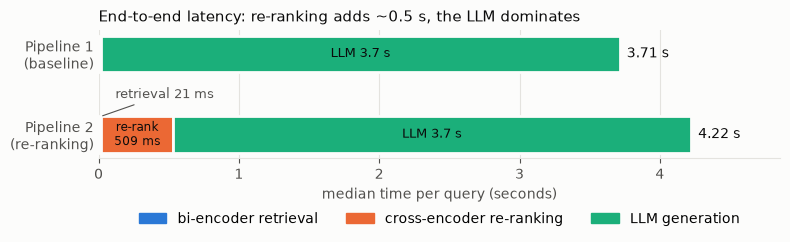

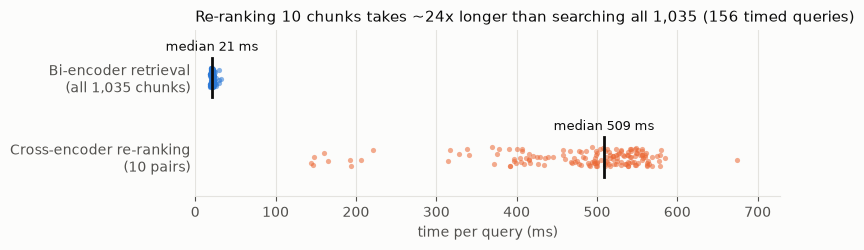

saved -> figures\latency_end_to_end.png and figures\latency_retrieval_vs_rerank.png


In [99]:
# Latency charts (uses t_retrieval, t_rerank, t_llm from the cell above); saved to figures/ for the report
import matplotlib.pyplot as plt

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# colours: one fixed colour per stage, used in both charts
C_RETR, C_RERANK, C_LLM = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "figure.facecolor": SURFACE,
                     "axes.facecolor": SURFACE})

med_r, med_ce, med_llm = np.median(t_retrieval), np.median(t_rerank), np.median(t_llm)

# ---------- chart 1: where the time goes, end to end (median per query) ----------
fig, ax = plt.subplots(figsize=(8, 2.8))
rows = {"Pipeline 1\n(baseline)": [med_r, 0, med_llm],
        "Pipeline 2\n(re-ranking)": [med_r, med_ce, med_llm]}
for y, (name, (r, ce, llm)) in enumerate(rows.items()):
    left = 0
    for val, col in ((r, C_RETR), (ce, C_RERANK), (llm, C_LLM)):
        if val:
            ax.barh(y, val / 1000, left=left / 1000, height=0.45, color=col,
                    edgecolor=SURFACE, linewidth=2)
            left += val
    ax.text(left / 1000 + 0.05, y, f"{left / 1000:.2f} s", va="center", color=INK)
    # direct labels inside the segments that are wide enough to hold text
    if ce:
        ax.text((r + ce / 2) / 1000, y, f"re-rank\n{ce:.0f} ms", ha="center", va="center", color=INK, fontsize=8.5)
    ax.text((r + ce + llm / 2) / 1000, y, f"LLM {llm / 1000:.1f} s", ha="center", va="center", color=INK, fontsize=9)
# the retrieval segment is a ~22 ms sliver: label it with a callout in the gap between the bars
ax.annotate(f"retrieval {med_r:.0f} ms", xy=(med_r / 2000, 0.78), xytext=(0.12, 0.5),
            ha="left", va="center", color=MUTED, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=0.8))

ax.set_yticks(range(len(rows)), list(rows))
ax.invert_yaxis()
ax.set_xlabel("median time per query (seconds)")
ax.set_xlim(0, (med_r + med_ce + med_llm) / 1000 * 1.15)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in (C_RETR, C_RERANK, C_LLM)],
          labels=["bi-encoder retrieval", "cross-encoder re-ranking", "LLM generation"],
          loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=3, frameon=False)
ax.set_title("End-to-end latency: re-ranking adds ~0.5 s, the LLM dominates", loc="left", color=INK, fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "latency_end_to_end.png", dpi=200, bbox_inches="tight")
plt.show()

# ---------- chart 2: retrieval vs re-ranking, every measured query ----------
fig, ax = plt.subplots(figsize=(8, 2.6))
rng = np.random.default_rng(0)
for y, (vals, col) in enumerate([(t_retrieval, C_RETR), (t_rerank, C_RERANK)]):
    jitter = rng.uniform(-0.12, 0.12, len(vals))
    ax.scatter(vals, y + jitter, s=14, color=col, alpha=0.55, linewidths=0)
    med = np.median(vals)
    ax.plot([med, med], [y - 0.25, y + 0.25], color=INK, linewidth=2)
    ax.text(med, y - 0.3, f"median {med:.0f} ms", ha="center", va="bottom", color=INK, fontsize=9)
ax.set_yticks([0, 1], ["Bi-encoder retrieval\n(all 1,035 chunks)", "Cross-encoder re-ranking\n(10 pairs)"])
ax.invert_yaxis()
ax.set_ylim(1.5, -0.6)
ax.set_xlabel("time per query (ms)")
ax.set_xlim(0, max(t_rerank) * 1.08)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title(f"Re-ranking 10 chunks takes ~{np.median(t_rerank) / np.median(t_retrieval):.0f}x longer "
             f"than searching all 1,035 ({len(t_retrieval)} timed queries)", loc="left", color=INK, fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "latency_retrieval_vs_rerank.png", dpi=200, bbox_inches="tight")
plt.show()
print("saved ->", FIG_DIR / "latency_end_to_end.png", "and", FIG_DIR / "latency_retrieval_vs_rerank.png")

## 10. Retrieval metrics

- **Recall@k**: fraction of *all* relevant chunks that appear in the top k
- **Reciprocal rank / MRR**: 1 / rank of the *first* relevant chunk, averaged over queries (ignores later hits)
- **nDCG@k**: every hit counts, discounted by `log2(rank + 1)`, divided by the best possible ordering
- **Hit@k**: is at least one relevant chunk in the top k?
- **Precision@3**: how much of the 3-chunk LLM context is relevant

Two views: the **selected cases** use clause-level relevance (exact chunk ids, but these cases were
picked because re-ranking helped, so they are biased in its favour); the **42 failure-mode queries**
use article-level relevance (any chunk of an expected article counts) and give the overall picture.

In [100]:
# Metric functions: ranked = chunk ids in rank order, relevant = set of chunk ids that answer the query
import math

def recall_at_k(ranked, relevant, k):
    """Fraction of ALL relevant chunks that appear in the top k."""
    hits = sum(1 for c in ranked[:k] if c in relevant)
    return hits / len(relevant)

def reciprocal_rank(ranked, relevant):
    """1 / rank of the FIRST relevant chunk (0 if none). Average over queries = MRR."""
    for rank, c in enumerate(ranked, start=1):
        if c in relevant:
            return 1 / rank
    return 0.0

def ndcg_at_k(ranked, relevant, k):
    """Every hit counts, discounted by log2(rank + 1); divided by the best possible ordering."""
    dcg = sum(1 / math.log2(rank + 1)
              for rank, c in enumerate(ranked[:k], start=1) if c in relevant)
    ideal_hits = min(len(relevant), k)                      # best case: all relevant at the top
    idcg = sum(1 / math.log2(rank + 1) for rank in range(1, ideal_hits + 1))
    return dcg / idcg if idcg else 0.0

# sanity check: relevant at ranks 1, 4, 8 + one relevant chunk that was never retrieved
_ranked = [f"c{i}" for i in range(1, 11)]
_relevant = {"c1", "c4", "c8", "c_missing"}
print("check:", recall_at_k(_ranked, _relevant, 5), reciprocal_rank(_ranked, _relevant),
      round(ndcg_at_k(_ranked, _relevant, 10), 2), "(expected 0.5 1.0 0.68)")

check: 0.5 1.0 0.68 (expected 0.5 1.0 0.68)


In [101]:
# Selected cases (clause-level relevance): baseline vs re-ranked
cases = json.loads((RESULTS_DIR / "selected_cases.json").read_text(encoding="utf-8"))

print(f"{'query':<57} {'pipeline':<10} {'R@3':>5} {'RR':>5} {'nDCG@10':>8}")
means = {}
for name, key in (("baseline", "bi_rank"), ("re-ranked", "ce_rank")):
    scores = []
    for case in cases:
        relevant = set(case["relevant"])
        # rebuild each pipeline's ranking from the saved rank shifts
        ranked = [s["chunk_id"] for s in sorted(case["rank_shifts"], key=lambda s: s[key])]
        m = (recall_at_k(ranked, relevant, 3), reciprocal_rank(ranked, relevant), ndcg_at_k(ranked, relevant, 10))
        scores.append(m)
        print(f"{case['query'][:57]:<57} {name:<10} {m[0]:>5.2f} {m[1]:>5.2f} {m[2]:>8.2f}")
    means[name] = np.mean(scores, axis=0)

print()
for name, (r3, mrr, ndcg) in means.items():
    print(f"MEAN {name:<10} Recall@3 {r3:.2f}   MRR {mrr:.2f}   nDCG@10 {ndcg:.2f}")

query                                                     pipeline     R@3    RR  nDCG@10
What is Article 370?                                      baseline    0.00  0.12     0.32
Can the Vice-President act as President?                  baseline    0.00  0.25     0.43
Who appoints the judges of a High Court?                  baseline    0.00  0.14     0.33
Who is the supreme commander of the Defence Forces?       baseline    0.00  0.25     0.43
Can the Council of States be dissolved?                   baseline    0.00  0.17     0.36
Does an accused person have the right to remain silent?   baseline    0.00  0.17     0.36
Is caste discrimination illegal?                          baseline    0.00  0.17     0.40
Is the President immune from court proceedings?           baseline    0.00  0.20     0.44
What is Article 370?                                      re-ranked   1.00  0.50     0.63
Can the Vice-President act as President?                  re-ranked   1.00  1.00     1.00
Who appoin

In [102]:
# All failure-mode queries with an expected article (article-level relevance): baseline vs re-ranked
def article_ranking(r, key):
    """Ranked list of ARTICLE numbers for one saved result (bi_rank = baseline, ce_rank = re-ranked)."""
    return [article_of(s["chunk_id"]) for s in sorted(r["rank_shifts"], key=lambda s: s[key])]

def hit_at_k(ranked, relevant, k):
    return float(any(c in relevant for c in ranked[:k]))

def precision_at_k(ranked, relevant, k):
    return sum(1 for c in ranked[:k] if c in relevant) / k

results = [r for f in sorted(RESULTS_DIR.glob("*.json")) if f.stem != "selected_cases"
           for r in json.loads(f.read_text(encoding="utf-8")) if r["expected_articles"]]

print(f"{len(results)} queries with an expected article\n")
print(f"{'metric':<12} {'baseline':>9} {'re-ranked':>10}")
for label, fn in [("Hit@1",       lambda rk, rel: hit_at_k(rk, rel, 1)),
                  ("Hit@3",       lambda rk, rel: hit_at_k(rk, rel, 3)),
                  ("Hit@10",      lambda rk, rel: hit_at_k(rk, rel, 10)),
                  ("MRR@10",      reciprocal_rank),
                  ("Precision@3", lambda rk, rel: precision_at_k(rk, rel, 3))]:
    base = np.mean([fn(article_ranking(r, "bi_rank"), set(r["expected_articles"])) for r in results])
    rr   = np.mean([fn(article_ranking(r, "ce_rank"), set(r["expected_articles"])) for r in results])
    print(f"{label:<12} {base:>9.3f} {rr:>10.3f}")

never = sum(1 for r in results if not r["expected_ranks"]["baseline"])
print(f"\n{never} of {len(results)} queries had no relevant chunk in the top 10 (re-ranking cannot help these).")
print("Hit@10 is identical for both pipelines by construction: re-ranking only reorders the same 10 chunks.")

48 queries with an expected article

metric        baseline  re-ranked
Hit@1            0.604      0.625
Hit@3            0.688      0.812
Hit@10           0.833      0.833
MRR@10           0.670      0.707
Precision@3      0.354      0.424

8 of 48 queries had no relevant chunk in the top 10 (re-ranking cannot help these).
Hit@10 is identical for both pipelines by construction: re-ranking only reorders the same 10 chunks.


In [103]:
# Per-query table: Recall@3, Precision@3, reciprocal rank and nDCG@10 for every failure-mode query
# relevance is article-level: a chunk counts as relevant if its article is in expected_articles
import csv

def dedup(articles):
    """Keep each article once, at its first (best) position - so nDCG can't exceed 1."""
    seen, out = set(), []
    for a in articles:
        if a not in seen:
            seen.add(a)
            out.append(a)
    return out

def query_metrics(r, key):
    """key = 'bi_rank' (baseline) or 'ce_rank' (re-ranked)."""
    expected = set(r["expected_articles"])
    ranked = article_ranking(r, key)                  # article of each chunk, in rank order (10 items)
    return {"R@3":  recall_at_k(dedup(ranked[:3]), expected, 3),     # share of expected articles in top 3
            "P@3":  precision_at_k(ranked, expected, 3),              # share of the 3 LLM chunks that are relevant
            "RR":   reciprocal_rank(ranked, expected),                # 1 / rank of first relevant chunk
            "nDCG": ndcg_at_k(dedup(ranked), expected, 10)}           # every relevant article, discounted by rank

rows = []
for f in sorted(QUERIES_DIR.glob("*.json")):
    saved = RESULTS_DIR / f.name
    for r in json.loads(saved.read_text(encoding="utf-8")):
        if not r["expected_articles"]:                # out-of-corpus: nothing to find
            continue
        rows.append({"mode": f.stem, "query": r["query"],
                     "base": query_metrics(r, "bi_rank"), "rr": query_metrics(r, "ce_rank")})

METRICS = ["R@3", "P@3", "RR", "nDCG"]
head = f"{'mode':<17} {'query':<50} " + " ".join(f"{m + ' b→r':>13}" for m in METRICS)
print(head)
print("-" * len(head))
for row in rows:
    cells = []
    for m in METRICS:
        b, a = row["base"][m], row["rr"][m]
        arrow = "▲" if a > b + 1e-9 else "▼" if a < b - 1e-9 else " "
        cells.append(f"{b:.2f}→{a:.2f} {arrow}".rjust(13))
    print(f"{row['mode']:<17} {row['query'][:50]:<50} " + " ".join(cells))
print("-" * len(head))
means = " ".join(f"{np.mean([r['base'][m] for r in rows]):.2f}→{np.mean([r['rr'][m] for r in rows]):.2f}  ".rjust(13)
                 for m in METRICS)
print(f"{'MEAN (' + str(len(rows)) + ' queries)':<68} {means}")
print("b→r = baseline → re-ranked;  ▲ better, ▼ worse after re-ranking")

# also save as CSV for the report
out = RESULTS_DIR / "metrics_per_query.csv"
with open(out, "w", newline="", encoding="utf-8") as fh:
    w = csv.writer(fh)
    w.writerow(["mode", "query"] + [f"{m}_{p}" for m in METRICS for p in ("baseline", "reranked")])
    for row in rows:
        w.writerow([row["mode"], row["query"]] +
                   [round(row[p][m], 3) for m in METRICS for p in ("base", "rr")])
print("saved ->", out)

mode              query                                                    R@3 b→r       P@3 b→r        RR b→r      nDCG b→r
----------------------------------------------------------------------------------------------------------------------------
document_specific What does Article 21 say?                            1.00→1.00     0.33→0.33     1.00→1.00     1.00→1.00  
document_specific What is Article 356 about?                           1.00→1.00     0.67→1.00 ▲   1.00→1.00     1.00→1.00  
document_specific What is Article 370?                                 1.00→1.00     0.33→0.67 ▲   0.50→1.00 ▲   0.63→1.00 ▲
document_specific Is the right to property a fundamental right?        0.00→0.00     0.00→0.00     0.00→0.00     0.00→0.00  
document_specific What does Article 31 say?                            0.00→0.00     0.00→0.00     0.00→0.00     0.00→0.00  
document_specific Can peaceful assembly be restricted in the interes   0.00→0.00     0.00→0.00     0.00→0.00     0.00→0.00  


In [ ]:
# Queries that failed completely: no chunk of an expected article in the bi-encoder top 10,
# so re-ranking had nothing to promote. For each: where the right article actually ranked among
# ALL chunks, and what was retrieved instead (retrieval only, no LLM calls).
failed = [(f.stem, r)
          for f in sorted(RESULTS_DIR.glob("*.json")) if f.stem != "selected_cases"
          for r in json.loads(f.read_text(encoding="utf-8"))
          if r["expected_articles"] and not r["expected_ranks"]["baseline"]]
print(f"{len(failed)} queries had no relevant chunk in the top 10\n")

ranks = []
for mode, r in failed:
    expected = set(r["expected_articles"])
    full, _ = retrieve(r["query"], k=len(chunks))               # rank every chunk, not just the top 10
    first = next(c for c in full if article_of(c["chunk_id"]) in expected)
    ranks.append(first["rank"])
    top3 = ", ".join(f"{c['chunk_id']} ({c['text'].splitlines()[0].split(' — ')[1][:38]})" for c in full[:3])

    print(f"[{mode}] {r['query']}")
    print(f"   expected article(s): {', '.join(sorted(expected))}")
    print(f"   first relevant chunk: {first['chunk_id']} at rank {first['rank']} of {len(chunks)} "
          f"(cosine {first['score']:.3f} vs #10 at {full[9]['score']:.3f})")
    print(f"   retrieved instead:   {top3}")
    print(f"   why: {r['note']}\n")

for k in (20, 50, 100):
    print(f"would be inside a top-{k} candidate pool: {sum(x <= k for x in ranks)} of {len(failed)}")